## Earlier historical-simulation notebook

Working copy that precedes `VaR_Estimation_of_nifty50_using_historical_method.ipynb`. The report's write-up (₹1 crore book, 501-day window, 99% VaR, AE ratio about 3.4) refers to that later notebook and to `Historical.md`. This file still estimates the 5th worst loss on 500 scenarios; use it to see the first version of the window logic.


In [90]:
# Shared dataset locator.
# The workbook and the two-year CSV live in the project data/ folder.
# Running this notebook from a method folder (Historical, GARCH, ...) or from
# the project root both resolve. Machine-specific paths from the original
# Colab / local drives are no longer required.
from pathlib import Path

def find_nifty_file(filename="Nifty50_data.xlsx"):
    """Return the first existing copy of a file under data/ or the working directory."""
    here = Path.cwd().resolve()
    candidates = [
        here / "data" / filename,
        here.parent / "data" / filename,
        here / filename,
    ]
    for path in candidates:
        if path.exists():
            return str(path.resolve())
    raise FileNotFoundError(
        f"Could not find {filename}. Open the notebook from the project folder "
        "or from its method folder so that data/ is visible."
    )

NIFTY_PATH = find_nifty_file("Nifty50_data.xlsx")
print("Using dataset:", NIFTY_PATH)


E:\MSDSM\Sem-4\FCP\Historical


In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import seaborn as sns

In [92]:
# Optional: Save to CSV
nifty_df = pd.read_excel(NIFTY_PATH)  # data/Nifty50_data.xlsx


In [93]:
# Define the initial portfolio value and calculate the number of shares purchased
initial_investment = 10000000 # Initial investment amount

shares_held = initial_investment/nifty_df['NIFTY Index'].iloc[0] # Number of shares purchased
# Calculate the portfolio value based on the number of shares held
nifty_df['Portfolio Value'] = shares_held * nifty_df['NIFTY Index']

In [94]:
nifty_df.head()
nf_train = nifty_df[['Dates', 'NIFTY Index', 'Portfolio Value']].iloc[0:501]

In [95]:
# Calculate daily returns
nf_train['Loss'] = nf_train['Portfolio Value'].diff() # Calculate the daily loss
nf_train.head()


,Dates,NIFTY Index,Portfolio Value,Loss
0,2005-01-04,2103.75,1.000000e+07,NaN
1,2005-01-05,2032.20,9.659893e+06,-340106.951872
2,2005-01-06,1998.35,9.498990e+06,-160903.149138
3,2005-01-07,2015.50,9.580511e+06,81521.093286
4,2005-01-10,1982.00,9.421272e+06,-159239.453357


In [96]:
# Create a list of losses and sort in descending order
losses = nf_train['Loss'].tolist()
losses.sort(reverse=True)  # Sort in descending order

# The fifth highest loss is the 99% VaR for a 500-day scenario
VaR_99 = losses[4]

print(f"The 1-day VaR at 99% confidence level is : ${VaR_99:.2f}")

The 1-day VaR at 99% confidence level is : $613666.07


In [97]:
# Calculate the index just after the 99th percentile
index_after_99th = int(len(losses) * 0.01)
print(f"Index after the 99th percentile: {index_after_99th}")

# Retrieve the loss at this index as the VaR value
VaR_99 = losses[index_after_99th-1]

print(f"The 1-day VaR at 99% confidence level is : ${VaR_99:.2f}")


Index after the 99th percentile: 5
The 1-day VaR at 99% confidence level is : $613666.07


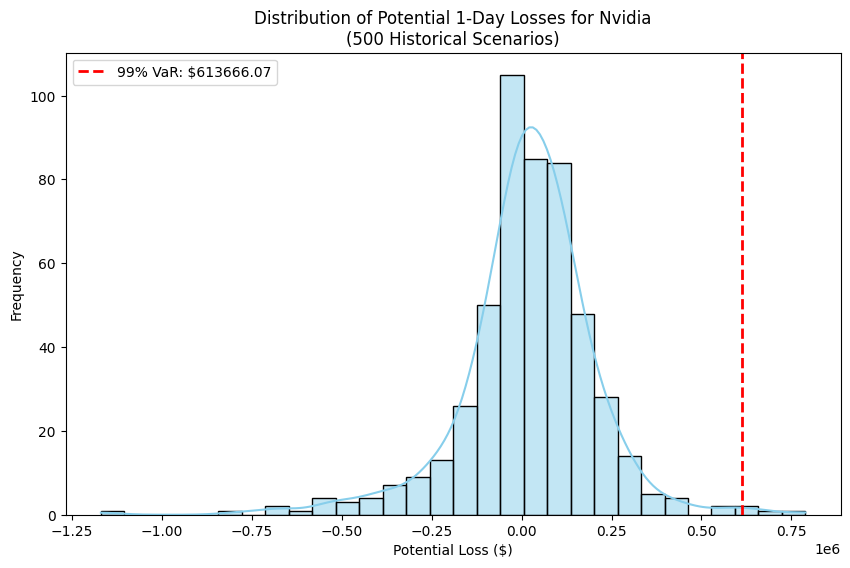

In [98]:
# Plotting the histogram
plt.figure(figsize=(10, 6))
sns.histplot(nf_train['Loss'], bins=30, kde=True, color='skyblue')

# Mark the VaR threshold on the histogram
plt.axvline(VaR_99, color='red', linestyle='--', linewidth=2, label=f'99% VaR: ${VaR_99:.2f}')

# Add labels and title
plt.title("Distribution of Potential 1-Day Losses for Nvidia\n(500 Historical Scenarios)")
plt.xlabel("Potential Loss ($)")
plt.ylabel("Frequency")
plt.legend()

# Show plot
plt.show()

In [99]:
nf_test=nifty_df[['Dates','NIFTY Index','Portfolio Value']].iloc[501:550]

# Calculate daily returns
nf_test['Loss'] = nf_test['Portfolio Value'].diff() # Calculate the daily loss
nf_test.head()

,Dates,NIFTY Index,Portfolio Value,Loss
501,2006-12-06,4015.95,1.908948e+07,NaN
502,2006-12-07,4015.35,1.908663e+07,-2852.049911
503,2006-12-08,3962.00,1.883304e+07,-253594.771242
504,2006-12-11,3849.50,1.829828e+07,-534759.358289
505,2006-12-12,3716.90,1.766797e+07,-630303.030303


In [100]:
# Identify days in the test set where the loss exceeds VaR_99
exceeded_VaR = nf_test[nf_test['Loss'] > VaR_99]

# Count the number of violations
num_violations = len(exceeded_VaR)

# Check if the number of violations is within the expected limit for 99% confidence
if num_violations > 1:
    print("The historical method does not hold with 99% confidence.")
else:
    print("The historical method holds with 99% confidence.")

print(f"Number of days where loss exceeded VaR99: {num_violations}")


The historical method holds with 99% confidence.
Number of days where loss exceeded VaR99: 0


In [101]:
# Automating for all windows of 501 days for training data
train_dfs = [
    nifty_df.iloc[i:i+501][['Dates', 'NIFTY Index', 'Portfolio Value']].assign(
        Loss=lambda df: df['Portfolio Value'].diff()
    )
    for i in range(len(nifty_df) - 501)
]

# Example: Accessing the first training set
train_dfs[1].head()


,Dates,NIFTY Index,Portfolio Value,Loss
1,2005-01-05,2032.20,9.659893e+06,NaN
2,2005-01-06,1998.35,9.498990e+06,-160903.149138
3,2005-01-07,2015.50,9.580511e+06,81521.093286
4,2005-01-10,1982.00,9.421272e+06,-159239.453357
5,2005-01-11,1952.05,9.278907e+06,-142364.824718


In [102]:
# Automating for all windows of 501 days for training data
test_dfs = [
    nifty_df.iloc[i:i+51][['Dates', 'NIFTY Index', 'Portfolio Value']].assign(
        Loss=lambda df: df['Portfolio Value'].diff()
    )
    for i in range(501,len(nifty_df))
]

# Example: Accessing the first training set
test_dfs[1].head()


,Dates,NIFTY Index,Portfolio Value,Loss
502,2006-12-07,4015.35,1.908663e+07,NaN
503,2006-12-08,3962.00,1.883304e+07,-253594.771242
504,2006-12-11,3849.50,1.829828e+07,-534759.358289
505,2006-12-12,3716.90,1.766797e+07,-630303.030303
506,2006-12-13,3765.20,1.789756e+07,229590.017825


In [103]:
len(train_dfs), len(test_dfs)

(4388, 4388)

Window 17: Number of days where loss exceeded VaR99: 1
Window 18: Number of days where loss exceeded VaR99: 1
Window 19: Number of days where loss exceeded VaR99: 1
Window 20: Number of days where loss exceeded VaR99: 1
Window 21: Number of days where loss exceeded VaR99: 1
Window 22: Number of days where loss exceeded VaR99: 1
Window 23: Number of days where loss exceeded VaR99: 1
Window 24: Number of days where loss exceeded VaR99: 1
Window 25: Number of days where loss exceeded VaR99: 1
Window 26: Number of days where loss exceeded VaR99: 1
Window 27: Number of days where loss exceeded VaR99: 1
Window 28: Number of days where loss exceeded VaR99: 1
Window 29: Number of days where loss exceeded VaR99: 1
Window 30: Number of days where loss exceeded VaR99: 1
Window 31: Number of days where loss exceeded VaR99: 1
Window 32: Number of days where loss exceeded VaR99: 1
Window 33: Number of days where loss exceeded VaR99: 1
Window 34: Number of days where loss exceeded VaR99: 1
Window 35:

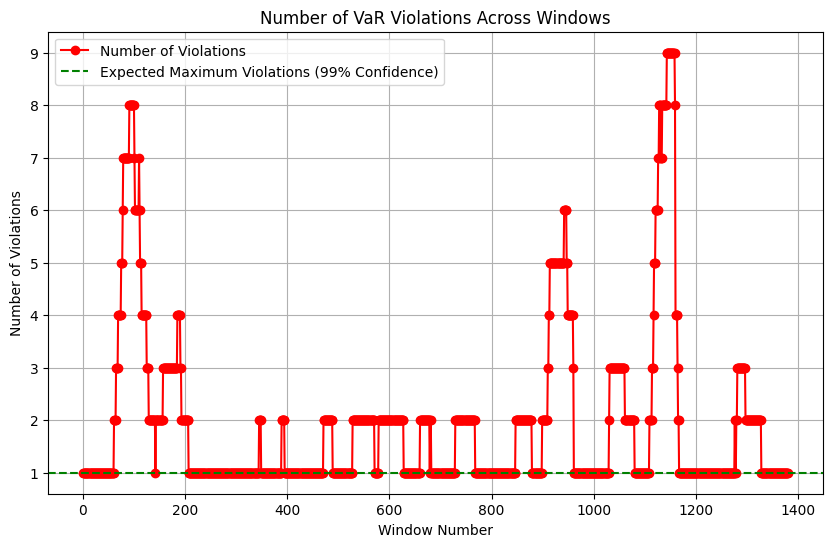

In [104]:
total_violations = 0
violated_windows = []

for i in range(len(train_dfs)):
    losses = train_dfs[i]['Loss'].tolist()
    losses.sort(reverse=True)  # Sort in descending order
    VaR_99 = losses[4]  # 99% VaR based on the 5th highest loss

    # Identify violations in the test data
    exceeded_VaR = test_dfs[i][test_dfs[i]['Loss'] > VaR_99]
    num_violations = len(exceeded_VaR)

    if num_violations > 0:
        violated_windows.append(num_violations)  # Track violations
        total_violations += num_violations
        print(f"Window {i+1}: Number of days where loss exceeded VaR99: {num_violations}")

# Summary of total violations
print(f"\nOut of all samples, {total_violations} violations were observed.")

# Plot the number of violations across all windows
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(violated_windows) + 1), violated_windows, marker='o', color='red', label='Number of Violations')
plt.title('Number of VaR Violations Across Windows')
plt.xlabel('Window Number')
plt.ylabel('Number of Violations')
plt.axhline(1, color='green', linestyle='--', label='Expected Maximum Violations (99% Confidence)')
plt.legend()
plt.grid(True)
plt.show()
